# 03 · Modelo de datos para Inteligencia de Negocios (Power BI)

**Proyecto integrador – Equipo 4** · Responsable: **Juana**

Este notebook diseña y genera el **modelo de datos en estrella** que alimenta el dashboard de Power BI. En un modelo estrella hay una **tabla de hechos** en el centro (cada venta, con sus cantidades e importes) rodeada de **dimensiones** (fecha, producto, cliente, país) que sirven para filtrar y agrupar.

**¿Por qué estrella y no una sola tabla plana?**
- Power BI está optimizado para este diseño: los filtros viajan de las dimensiones a los hechos y las medidas DAX son más simples.
- Los atributos se guardan una sola vez (p. ej. la región de un país) y no se repiten en un millón de filas.
- Las dimensiones se pueden enriquecer sin tocar los hechos (segmento RFM del cliente, clase ABC del producto, festivos).

**Audiencias del dashboard:**

| Página | Audiencia | Pregunta que responde |
|---|---|---|
| Resumen ejecutivo | Gerencia | ¿Cómo vamos en ventas, pedidos, clientes y devoluciones frente al año anterior? |
| Productos | Compras / categoría | ¿Qué productos sostienen el negocio (ABC) y cuáles se devuelven más? |
| Clientes y mercados | Comercial / marketing | ¿Qué clientes retener (RFM) y en qué países crecer? |
| Pronóstico de demanda | Inventario / operaciones | ¿Cuánto reponer la próxima semana y qué tan confiable es el pronóstico? |

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from src import config, modelo_datos
from src import visualizacion as viz
viz.aplicar_estilo()

## 1. Reglas de negocio para los indicadores (KPI)
Estas definiciones se acordaron para que todo el equipo calcule igual cada cifra. Se implementan como medidas DAX en `dashboard/medidas_dax.md`.

| KPI | Definición | Regla |
|---|---|---|
| Ventas brutas | Suma del importe de las líneas de **venta** | `tipo_transaccion = "Venta"` |
| Devoluciones | Suma del importe de las líneas de **devolución** (en positivo) | `tipo_transaccion = "Devolución"` |
| Ventas netas | Ventas brutas − devoluciones | Suma de todo el importe |
| Tasa de devolución | Devoluciones ÷ ventas brutas | Meta de referencia: < 3 % |
| Pedidos | Facturas de venta distintas | No cuenta facturas C |
| Ticket promedio | Ventas brutas ÷ pedidos | |
| Clientes activos | Clientes identificados distintos con al menos una venta | Excluye "SIN REGISTRO" |
| Variación interanual | Ventas netas del periodo ÷ mismo periodo del año anterior − 1 | Usa la dimensión fecha |
| Clase ABC | A = productos que suman el 80 % del ingreso; B = siguiente 15 %; C = último 5 % | Calculada sobre ventas brutas |
| Segmento RFM | Recencia, frecuencia y valor monetario en quintiles (1 a 5) | Ver tabla de segmentos más abajo |

## 2. Diagrama del modelo estrella

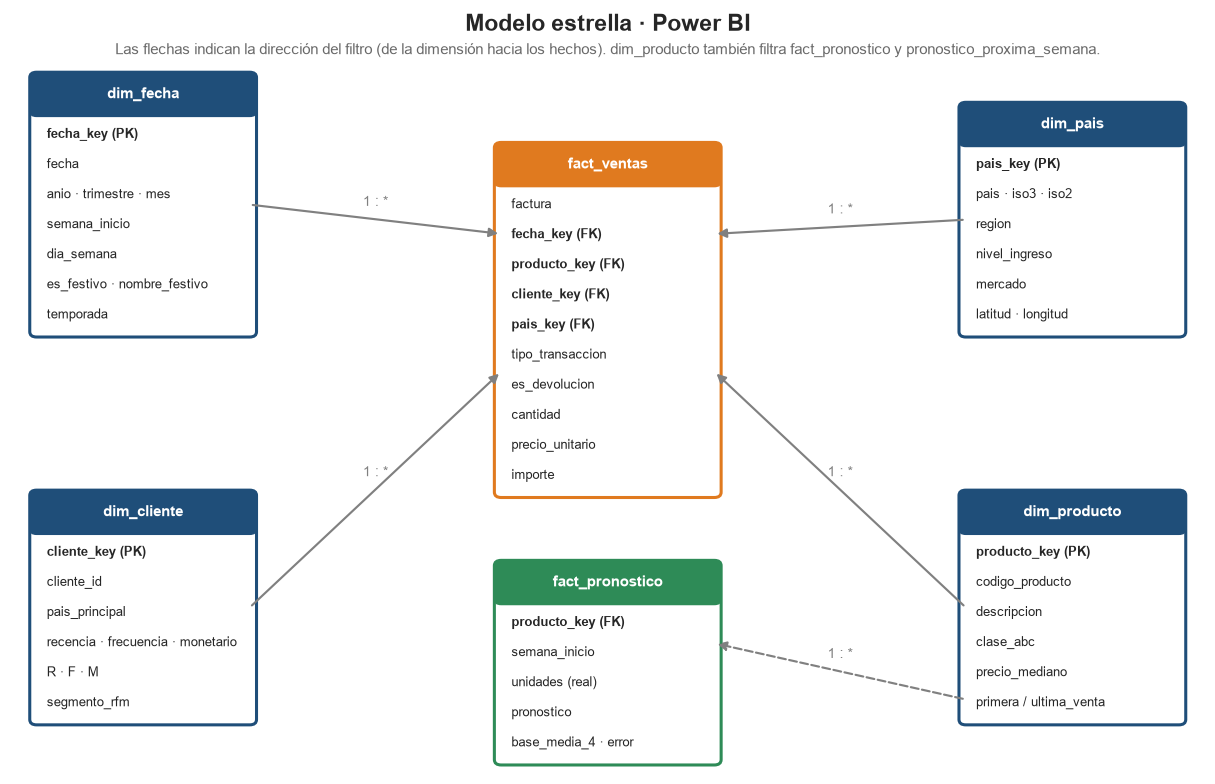

In [2]:
def caja(ax, x, y, titulo, campos, color, ancho=0.25):
    alto = 0.045 * (len(campos) + 1) + 0.02
    ax.add_patch(FancyBboxPatch((x, y), ancho, alto, boxstyle="round,pad=0.008", fc="white", ec=color, lw=2))
    ax.add_patch(FancyBboxPatch((x, y + alto - 0.05), ancho, 0.05, boxstyle="round,pad=0.008", fc=color, ec=color))
    ax.text(x + ancho / 2, y + alto - 0.025, titulo, ha="center", va="center", color="white", weight="bold", fontsize=10)
    for i, c in enumerate(campos):
        ax.text(x + 0.012, y + alto - 0.085 - i * 0.045, c, fontsize=8.5, va="center",
                weight="bold" if "key" in c else "normal")
    return (x, y, ancho, alto)

def flecha(ax, origen, destino, texto="1 : *", estilo="-"):
    ax.annotate("", xy=destino, xytext=origen,
                arrowprops=dict(arrowstyle="-|>", color="gray", lw=1.4, linestyle=estilo))
    ax.text((origen[0] + destino[0]) / 2, (origen[1] + destino[1]) / 2 + 0.02, texto,
            fontsize=9, color="gray", ha="center")

fig, ax = plt.subplots(figsize=(14, 9))
ax.set_xlim(0, 1.4); ax.set_ylim(0, 1.14); ax.axis("off")
FX, FY, FW = 0.575, 0.42, 0.25
f = caja(ax, FX, FY, "fact_ventas", ["factura", "fecha_key (FK)", "producto_key (FK)", "cliente_key (FK)",
         "pais_key (FK)", "tipo_transaccion", "es_devolucion", "cantidad", "precio_unitario", "importe"], viz.NARANJA)
p = caja(ax, FX, 0.02, "fact_pronostico", ["producto_key (FK)", "semana_inicio", "unidades (real)", "pronostico",
                                           "base_media_4 · error"], viz.VERDE)
dims = [
    (0.03, 0.66, "dim_fecha", ["fecha_key (PK)", "fecha", "anio · trimestre · mes", "semana_inicio", "dia_semana",
                               "es_festivo · nombre_festivo", "temporada"], 0.75),
    (1.12, 0.66, "dim_pais", ["pais_key (PK)", "pais · iso3 · iso2", "region", "nivel_ingreso", "mercado",
                              "latitud · longitud"], 0.75),
    (0.03, 0.08, "dim_cliente", ["cliente_key (PK)", "cliente_id", "pais_principal", "recencia · frecuencia · monetario",
                                 "R · F · M", "segmento_rfm"], 0.35),
    (1.12, 0.08, "dim_producto", ["producto_key (PK)", "codigo_producto", "descripcion", "clase_abc",
                                  "precio_mediano", "primera / ultima_venta"], 0.35),
]
for x, y, t, c, frac in dims:
    b = caja(ax, x, y, t, c, viz.AZUL)
    izquierda = x < FX
    origen = (b[0] + b[2] if izquierda else b[0], b[1] + b[3] / 2)
    destino = (FX if izquierda else FX + FW, FY + frac * f[3])
    flecha(ax, origen, destino)
    if t == "dim_producto":
        flecha(ax, (b[0], b[1] + 0.03), (FX + FW, p[1] + p[3] * 0.6), estilo="--")
ax.text(0.7, 1.11, "Modelo estrella · Power BI", ha="center", fontsize=15, weight="bold")
ax.text(0.7, 1.075, "Las flechas indican la dirección del filtro (de la dimensión hacia los hechos). "
        "dim_producto también filtra fact_pronostico y pronostico_proxima_semana.", ha="center", fontsize=9.5, color="dimgray")
viz.guardar(fig, "bi_modelo_estrella")
plt.show()

## 3. Construcción de las tablas
`construir_modelo_estrella()` lee la salida del ETL (y del modelo predictivo, si ya se ejecutó) y escribe los CSV en `data/bi/`.

In [3]:
tablas = modelo_datos.construir_modelo_estrella(guardar=True)

dim_fecha                          739 filas
dim_producto                     4,737 filas
dim_cliente                      5,876 filas
dim_pais                            43 filas


fact_ventas                  1,021,239 filas
fact_pronostico                  3,600 filas
pronostico_proxima_semana          300 filas
metricas_modelo                      6 filas


In [4]:
for nombre in ["dim_fecha", "dim_producto", "dim_cliente", "dim_pais", "fact_ventas"]:
    print(f"\n=== {nombre} ({len(tablas[nombre]):,} filas) ===")
    display(tablas[nombre].head(3))


=== dim_fecha (739 filas) ===


,fecha_key,fecha,anio,trimestre,mes_num,mes,anio_mes,semana_inicio,dia_semana_num,dia_semana,es_festivo,nombre_festivo,temporada
0,20091201,2009-12-01,2009,T4,12,Diciembre,2009-12,2009-11-30,2,Martes,False,,Navidad (dic)
1,20091202,2009-12-02,2009,T4,12,Diciembre,2009-12,2009-11-30,3,Miércoles,False,,Navidad (dic)
2,20091203,2009-12-03,2009,T4,12,Diciembre,2009-12,2009-11-30,4,Jueves,False,,Navidad (dic)



=== dim_producto (4,737 filas) ===


,producto_key,codigo_producto,descripcion,precio_mediano,primera_venta,ultima_venta,clase_abc
0,1,10002,INFLATABLE POLITICAL GLOBE,0.85,2009-12-01,2011-04-18,A
1,2,10002R,ROBOT PENCIL SHARPNER,5.17,2009-12-02,2010-01-25,C
2,3,10080,GROOVY CACTUS INFLATABLE,0.39,2009-12-02,2011-11-21,C



=== dim_cliente (5,876 filas) ===


,cliente_key,cliente_id,pais_principal,primera_compra,ultima_compra,recencia_dias,frecuencia,monetario,R,F,M,segmento_rfm
0,1,12346,United Kingdom,2010-03-02,2010-06-28,530.00,2.00,169.36,1.00,2.00,1.00,Perdidos
1,2,12347,Iceland,2010-10-31,2011-12-07,3.00,8.00,"4,921.53",5.00,4.00,5.00,Campeones
2,3,12348,Finland,2010-09-27,2011-09-25,76.00,5.00,"1,658.40",3.00,4.00,4.00,Leales



=== dim_pais (43 filas) ===


,pais_key,pais,iso3,region,nivel_ingreso,iso2,capital,latitud,longitud,mercado
0,1,Australia,AUS,Asia Oriental y Pacífico,Ingreso alto,AU,Canberra,-35.28,149.13,Internacional
1,2,Austria,AUT,Europa y Asia Central,Ingreso alto,AT,Vienna,48.22,16.38,Internacional
2,3,Bahrain,BHR,Medio Oriente y Norte de África,Ingreso alto,BH,Manama,26.19,50.54,Internacional



=== fact_ventas (1,021,239 filas) ===


,factura,fecha_key,hora,producto_key,cliente_key,pais_key,tipo_transaccion,es_devolucion,cantidad,precio_unitario,importe
0,489434,20091201,7,4093,727,42,Venta,0,12,6.95,83.40
1,489434,20091201,7,3407,727,42,Venta,0,12,6.75,81.00
2,489434,20091201,7,3409,727,42,Venta,0,12,6.75,81.00


## 4. Validación del modelo
Integridad referencial (toda fila de hechos encuentra su dimensión) y unicidad de las claves primarias.

In [5]:
modelo_datos.validar_modelo(tablas)

,prueba,resultado
0,Claves únicas en dim_fecha,OK
1,Claves únicas en dim_producto,OK
2,Claves únicas en dim_cliente,OK
3,Claves únicas en dim_pais,OK
4,Toda venta tiene fecha,OK
5,Toda venta tiene producto,OK
6,Toda venta tiene cliente,OK
7,Toda venta tiene país,OK


## 5. Segmentación de clientes (RFM)
Cada cliente recibe un puntaje de 1 a 5 en **Recencia** (qué tan reciente fue su última compra), **Frecuencia** (cuántos pedidos) y **Monetario** (cuánto gastó). Con R y F se asigna un segmento con nombre de negocio.

In [6]:
cli = tablas["dim_cliente"][~tablas["dim_cliente"]["segmento_rfm"].isin(["Sin registro", "Solo devoluciones"])]
rfm = (cli.groupby("segmento_rfm")
       .agg(clientes=("cliente_id", "count"), ingreso=("monetario", "sum"),
            recencia_mediana_dias=("recencia_dias", "median"), pedidos_medianos=("frecuencia", "median"))
       .sort_values("ingreso", ascending=False))
rfm["% clientes"] = rfm["clientes"] / rfm["clientes"].sum() * 100
rfm["% ingreso"] = rfm["ingreso"] / rfm["ingreso"].sum() * 100
acciones = {"Campeones": "Fidelizar: acceso anticipado a novedades, condiciones preferentes",
            "Leales": "Venta cruzada y programa de puntos", "En riesgo": "Contacto comercial directo y oferta de reactivación",
            "Nuevos o recientes": "Bienvenida y segunda compra incentivada", "Necesitan atención": "Recordatorios y promociones de temporada",
            "Perdidos": "Campaña de bajo costo; no priorizar"}
rfm["acción sugerida"] = rfm.index.map(acciones)
rfm.round(1)

,clientes,ingreso,recencia_mediana_dias,pedidos_medianos,% clientes,% ingreso,acción sugerida
segmento_rfm,,,,,,,
Campeones,1469,"11,781,002.80",17.00,10.00,25.10,70.10,"Fidelizar: acceso anticipado a novedades, cond..."
Leales,1213,"2,444,116.60",73.00,4.00,20.70,14.50,Venta cruzada y programa de puntos
En riesgo,829,"1,511,701.60",374.00,4.00,14.20,9.00,Contacto comercial directo y oferta de reactiv...
Perdidos,1511,"619,759.20",433.00,1.00,25.80,3.70,Campaña de bajo costo; no priorizar
Nuevos o recientes,447,"243,417.10",27.00,1.00,7.60,1.40,Bienvenida y segunda compra incentivada
Necesitan atención,383,"205,350.60",93.00,1.00,6.50,1.20,Recordatorios y promociones de temporada


## 6. Clasificación ABC de productos

In [7]:
v = pd.read_parquet(config.VENTAS_LIMPIAS, columns=["codigo_producto", "tipo_transaccion", "importe"])
ing = v[v["tipo_transaccion"] == "Venta"].groupby("codigo_producto")["importe"].sum()
abc = tablas["dim_producto"].assign(ingreso=lambda d: d["codigo_producto"].map(ing).fillna(0))
res = abc.groupby("clase_abc").agg(productos=("producto_key", "count"), ingreso=("ingreso", "sum"))
res["% productos"] = res["productos"] / res["productos"].sum() * 100
res["% ingreso"] = res["ingreso"] / res["ingreso"].sum() * 100
res.round(1)

,productos,ingreso,% productos,% ingreso
clase_abc,,,,
A,1039,"15,503,206.30",21.90,80.00
B,1260,"2,908,060.00",26.60,15.00
C,2424,"969,360.60",51.20,5.00
Sin ventas,14,0.00,0.30,0.00


## 7. Valores de control para verificar el dashboard
Al construir el dashboard en Power BI, las tarjetas **deben mostrar exactamente estas cifras** sin filtros aplicados. Si no coinciden, hay un error en una relación o en una medida DAX.

In [8]:
f = tablas["fact_ventas"]
fe = tablas["dim_fecha"].set_index("fecha_key")["fecha"]
f = f.assign(fecha=f["fecha_key"].map(fe))
venta, dev = f[f["es_devolucion"] == 0], f[f["es_devolucion"] == 1]
reg = tablas["dim_cliente"].set_index("cliente_key")["cliente_id"]
eneno = lambda d, a: d[(d["fecha"].dt.year == a) & (d["fecha"].dt.month <= 11)]["importe"].sum()
control = pd.Series({
    "Ventas netas (GBP)": f["importe"].sum(),
    "Ventas brutas (GBP)": venta["importe"].sum(),
    "Devoluciones (GBP)": -dev["importe"].sum(),
    "Tasa de devolución (%)": -dev["importe"].sum() / venta["importe"].sum() * 100,
    "Pedidos": venta["factura"].nunique(),
    "Ticket promedio (GBP)": venta["importe"].sum() / venta["factura"].nunique(),
    "Clientes activos": venta.loc[venta["cliente_key"].map(reg) != "SIN REGISTRO", "cliente_key"].nunique(),
    "Unidades vendidas": venta["cantidad"].sum(),
    "Ventas netas ene-nov 2010 (GBP)": eneno(f, 2010),
    "Ventas netas ene-nov 2011 (GBP)": eneno(f, 2011),
    "Variación ene-nov 2011 vs 2010 (%)": (eneno(f, 2011) / eneno(f, 2010) - 1) * 100,
})
control.map(lambda x: f"{x:,.2f}").to_frame("valor esperado")

,valor esperado
Ventas netas (GBP),"18,909,854.20"
Ventas brutas (GBP),"19,380,626.97"
Devoluciones (GBP),"470,772.77"
Tasa de devolución (%),2.43
Pedidos,"39,513.00"
Ticket promedio (GBP),490.49
Clientes activos,"5,852.00"
Unidades vendidas,"10,922,235.00"
Ventas netas ene-nov 2010 (GBP),"8,360,744.81"
Ventas netas ene-nov 2011 (GBP),"8,572,276.25"


## 8. Cómo se usa en Power BI
1. Ejecutar `python -m src.etl`, luego el notebook `04_modelo_predictivo.ipynb` y por último `python -m src.modelo_datos` (o este notebook).
2. En Power BI Desktop: **Obtener datos → Texto/CSV** y cargar los archivos de `data/bi/`.
3. Crear las relaciones del diagrama, las medidas de `dashboard/medidas_dax.md` y las páginas descritas en `dashboard/guia_power_bi.md`.
4. Comparar las tarjetas con los **valores de control** de la sección 7.

**Conclusión:** el modelo estrella queda validado (claves únicas e integridad referencial en OK). Integra las tres fuentes del ETL y las salidas del modelo predictivo, y está listo para un dashboard que sirve a cuatro audiencias distintas.